# Confirmation Versus Shrinkage in Coding Confidence

Does fresh-data confirmation improve a subgroup correction beyond independent estimation and an ordinary smaller update?

The earlier experiment changed the discovery pool, estimator, shrinkage and gate together. This follow-up separates those components for one frozen rule. It uses the inspected coding archive for development, newly replicated known-probability simulations, and a frozen transfer check on a separate benchmark.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT = next(path for path in [Path.cwd(), *Path.cwd().parents]
               if (path / "research" / "confirmation_protocol.json").exists())
RESULTS = PROJECT / "confirmation_results"

import sys
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from research.data import digest
from research.confirmation_study import role_counts

summary = json.loads((RESULTS / "summary.json").read_text())
protocol = json.loads((RESULTS / "protocol.json").read_text())
manifest = json.loads((RESULTS / "manifest.json").read_text())
for name, expected in manifest["files"].items():
    assert digest(RESULTS / name) == expected, name
assert not summary["smoke"] and summary["source_folds"] == 5
assert len(summary["simulation_seeds"]) == 100
assert summary["external_evaluated"]
assert digest(RESULTS / "protocol.json") == summary["protocol_sha256"]
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
print("Source task clusters:", summary["source_task_clusters"])
print("Independent fitting seeds per synthetic setting:", len(summary["simulation_seeds"]))
print("Verified all published numerical artifacts.")

Source task clusters: 1055
Independent fitting seeds per synthetic setting: 100
Verified all published numerical artifacts.


## 1. Hold the proposed correction fixed

Discovery D selects one residual-tree rule. Matched task samples from D and an independent set E estimate its size. The confirmation gate uses a third set C. All four arms share the rule, task-support requirement and step 0.5:

| Arm | Residual estimate | Confirmation |
| --- | --- | --- |
| Discovery fixed | Reused D tasks | None |
| Independent fixed | Independent E tasks | None |
| Discovery gated | Same reused estimate | C gate |
| Independent gated | Same independent estimate | Same C gate |

Two controls tune the D-rule step on validation tasks V. A pooled control spends D+E+C on its own rule and tunes on the same V. The step grid includes zero. These controls distinguish the gate's mechanism from the practical value of reserving labels for it.

The matched estimates use the same number of represented tasks, although qualifying candidate counts can differ. The C gate confirms the full-D proposal's direction; it does not guarantee the estimated update will help.

In [2]:
display(pd.DataFrame([
    {"available tasks": budget, **role_counts(budget, protocol["budget_fractions"])}
    for budget in protocol["source"]["budgets"]
]))
models = json.loads((RESULTS / "fitted_models.json").read_text())
budget = str(protocol["source"]["external_primary_budget"])
proposals = []
for model in models:
    fit = model["budgets"][budget]
    proposals.append({"fold": model["fold"], "status": fit["status"],
                      "discovery tasks in rule": fit["support"]["discovery"],
                      "matched estimate tasks": fit["matched_estimation"]["tasks"],
                      "confirmation tasks in rule": fit["support"]["confirmation"],
                      "gate accepted": fit["gate"]["accepted"],
                      "pooled selected step": fit["methods"]["pooled_shrinkage"]["step"]})
display(pd.DataFrame(proposals))

,available tasks,discovery,estimation,confirmation,validation
0,120,48,24,24,24
1,240,96,48,48,48
2,339,135,67,67,70


,fold,status,discovery tasks in rule,matched estimate tasks,confirmation tasks in rule,gate accepted,pooled selected step
0,0,eligible,21,11,12,False,0.500000
1,1,eligible,22,12,12,False,1.000000
2,2,eligible,23,12,11,False,0.000000
3,3,eligible,27,11,11,True,0.250000
4,4,eligible,24,19,20,False,1.000000


## 2. Recheck the coding archive

The five outer folds keep task siblings together. Every experimental arm starts from the same fold-specific Platt scores; raw logistic is an additional reference. The table shows the largest audit/tuning budget, 339 tasks.

This archive was already inspected. Task-bootstrap contrasts are descriptive and conditional on overlapping source fits. They are not independent replications of a new coding benchmark. The nonempty-code subset checks whether a result depends on recognizing empty extracted programs.

In [3]:
source = pd.read_csv(RESULTS / "source_metrics.csv")
main_source = source[source["budget"] == int(budget)]
display(main_source.groupby("method")[["brier", "log_loss"]].mean().sort_values("brier"))
nonempty = main_source.assign(weighted_loss=lambda frame: frame["nonempty_brier"] * frame["nonempty_candidates"])
nonempty = nonempty.groupby("method")[["weighted_loss", "nonempty_candidates"]].sum()
nonempty["nonempty_brier"] = nonempty["weighted_loss"] / nonempty["nonempty_candidates"]
display(nonempty[["nonempty_brier", "nonempty_candidates"]].sort_values("nonempty_brier"))
source_contrasts = pd.read_csv(RESULTS / "source_contrasts.csv")
display(source_contrasts[source_contrasts["budget"] == int(budget)]
        [["contrast", "difference", "low", "high", "task_clusters"]])

,brier,log_loss
method,,
raw_logistic,0.107111,0.324933
discovery_fixed,0.109003,0.329784
independent_shrinkage,0.109328,0.330477
independent_fixed,0.109506,0.330906
independent_gated,0.109816,0.331644
discovery_gated,0.109823,0.331656
no_update,0.110035,0.332088
discovery_shrinkage,0.110361,0.333150
pooled_shrinkage,0.110465,0.333576


,nonempty_brier,nonempty_candidates
method,,
raw_logistic,0.144910,7798
discovery_fixed,0.147465,7798
independent_shrinkage,0.147905,7798
independent_fixed,0.148146,7798
independent_gated,0.148565,7798
discovery_gated,0.148574,7798
no_update,0.148861,7798
discovery_shrinkage,0.149303,7798
pooled_shrinkage,0.149443,7798


,contrast,difference,low,high,task_clusters
12,gate_with_independent_estimate,0.000310,-0.000002,0.000632,1055
13,gate_with_reused_estimate,0.000820,-0.000211,0.001911,1055
14,independent_vs_reused_estimate,0.000503,-0.000383,0.001412,1055
15,gate_vs_tuned_independent,0.000488,-0.000143,0.001155,1055
16,gate_vs_pooled_shrinkage,-0.000649,-0.001988,0.000662,1055
17,gate_estimator_interaction,-0.000510,-0.001409,0.000374,1055


## 3. Separate selected noise from real signal

Each of 24 settings has 100 independent fitting seeds: four bias scenarios, three total label budgets, and either independent candidate label draws or a task-shared draw. Test tasks are generated independently. Known-probability MSE measures distortion directly.

Under the calibrated null, any score change is a false update. Its frequency gets an exact binomial Monte Carlo interval across fitting seeds. Under alternatives, a harmful update means increased known-probability MSE; it is a different failure from a false subgroup claim. The main curves show task-shared draws, with bands of mean ± 1.96 Monte Carlo standard errors.

,budget,method,update_rate,update_low,update_high,common_proposal_eligibility_rate
24,120,discovery_fixed,0.210000,0.134944,0.302915,0.210000
25,120,discovery_gated,0.000000,0.000000,0.036217,0.210000
26,120,discovery_shrinkage,0.090000,0.041984,0.163982,0.210000
27,120,independent_fixed,0.210000,0.134944,0.302915,0.210000
28,120,independent_gated,0.000000,0.000000,0.036217,0.210000
29,120,independent_shrinkage,0.090000,0.041984,0.163982,0.210000
30,120,no_update,0.000000,0.000000,0.036217,0.210000
31,120,pooled_shrinkage,0.480000,0.379005,0.582210,0.210000
32,360,discovery_fixed,0.900000,0.823777,0.950995,0.900000
33,360,discovery_gated,0.080000,0.035172,0.151558,0.900000


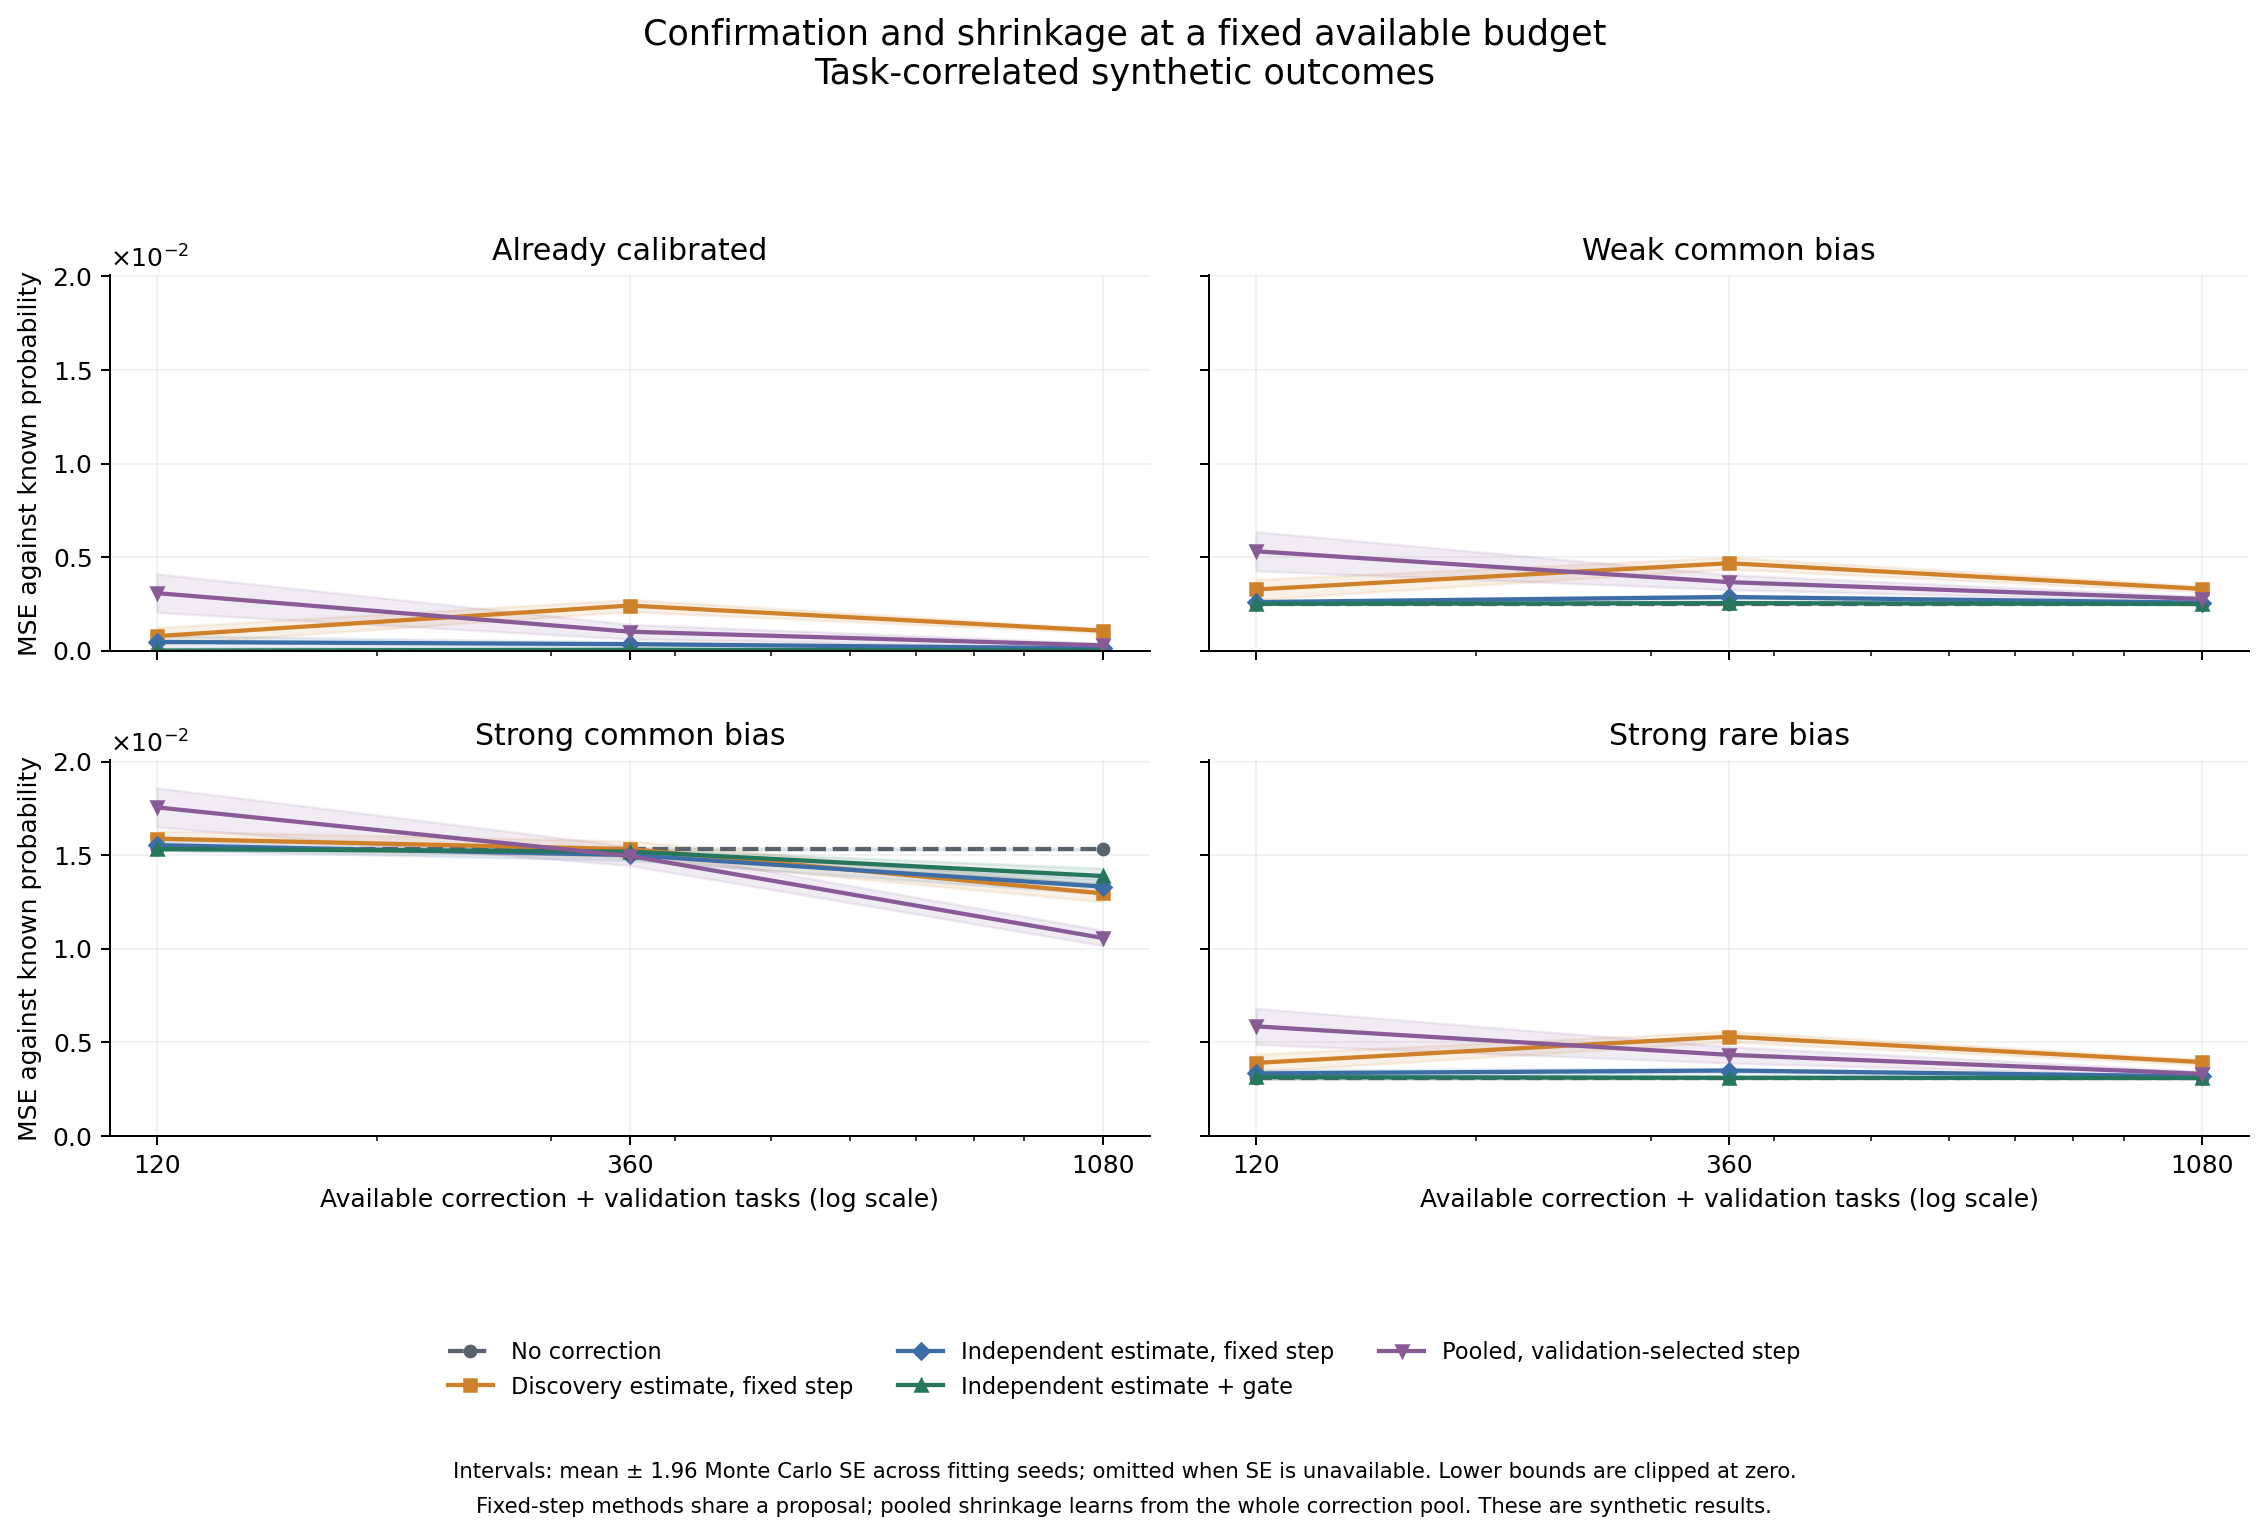

In [4]:
simulations = pd.read_csv(RESULTS / "simulation_summary.csv")
assert simulations["seeds"].eq(100).all()
null = simulations[(simulations["scenario"] == "calibrated_null") & simulations["shared_uniform"]]
display(null[["budget", "method", "update_rate", "update_low", "update_high", "common_proposal_eligibility_rate"]])
display(Image(filename=str(RESULTS / "confirmation_diagnostics.png")))

## 4. Measure the incremental gate effect

The primary contrast is independent gated minus independent fixed. A negative MSE difference favors the gate. Both arms use the same rule, estimate, step and membership-only eligibility check.

Intervals below resample complete fitting-seed replicates, capturing variation in the fitted procedure for each specified generator. They do not provide simultaneous coverage across settings. The gate's acceptance among rules with a finite-test-pool oracle residual above 0.03 is a diagnostic; it is not exact population power or false-discovery control.

,scenario,shared_uniform,budget,difference,low,high,seeds
0,calibrated_null,False,120,-0.000054,-0.000091,-0.000024,100
6,calibrated_null,False,360,-0.000082,-0.000110,-0.000057,100
12,calibrated_null,False,1080,-0.000028,-0.000039,-0.000019,100
18,calibrated_null,True,120,-0.000461,-0.000814,-0.000159,100
24,calibrated_null,True,360,-0.000301,-0.000413,-0.000201,100
30,calibrated_null,True,1080,-0.000116,-0.000150,-0.000087,100
36,strong_common,False,120,0.000088,-0.000000,0.000206,100
42,strong_common,False,360,0.000187,0.000055,0.000350,100
48,strong_common,False,1080,0.000000,0.000000,0.000000,100
54,strong_common,True,120,-0.000209,-0.000490,0.000005,100


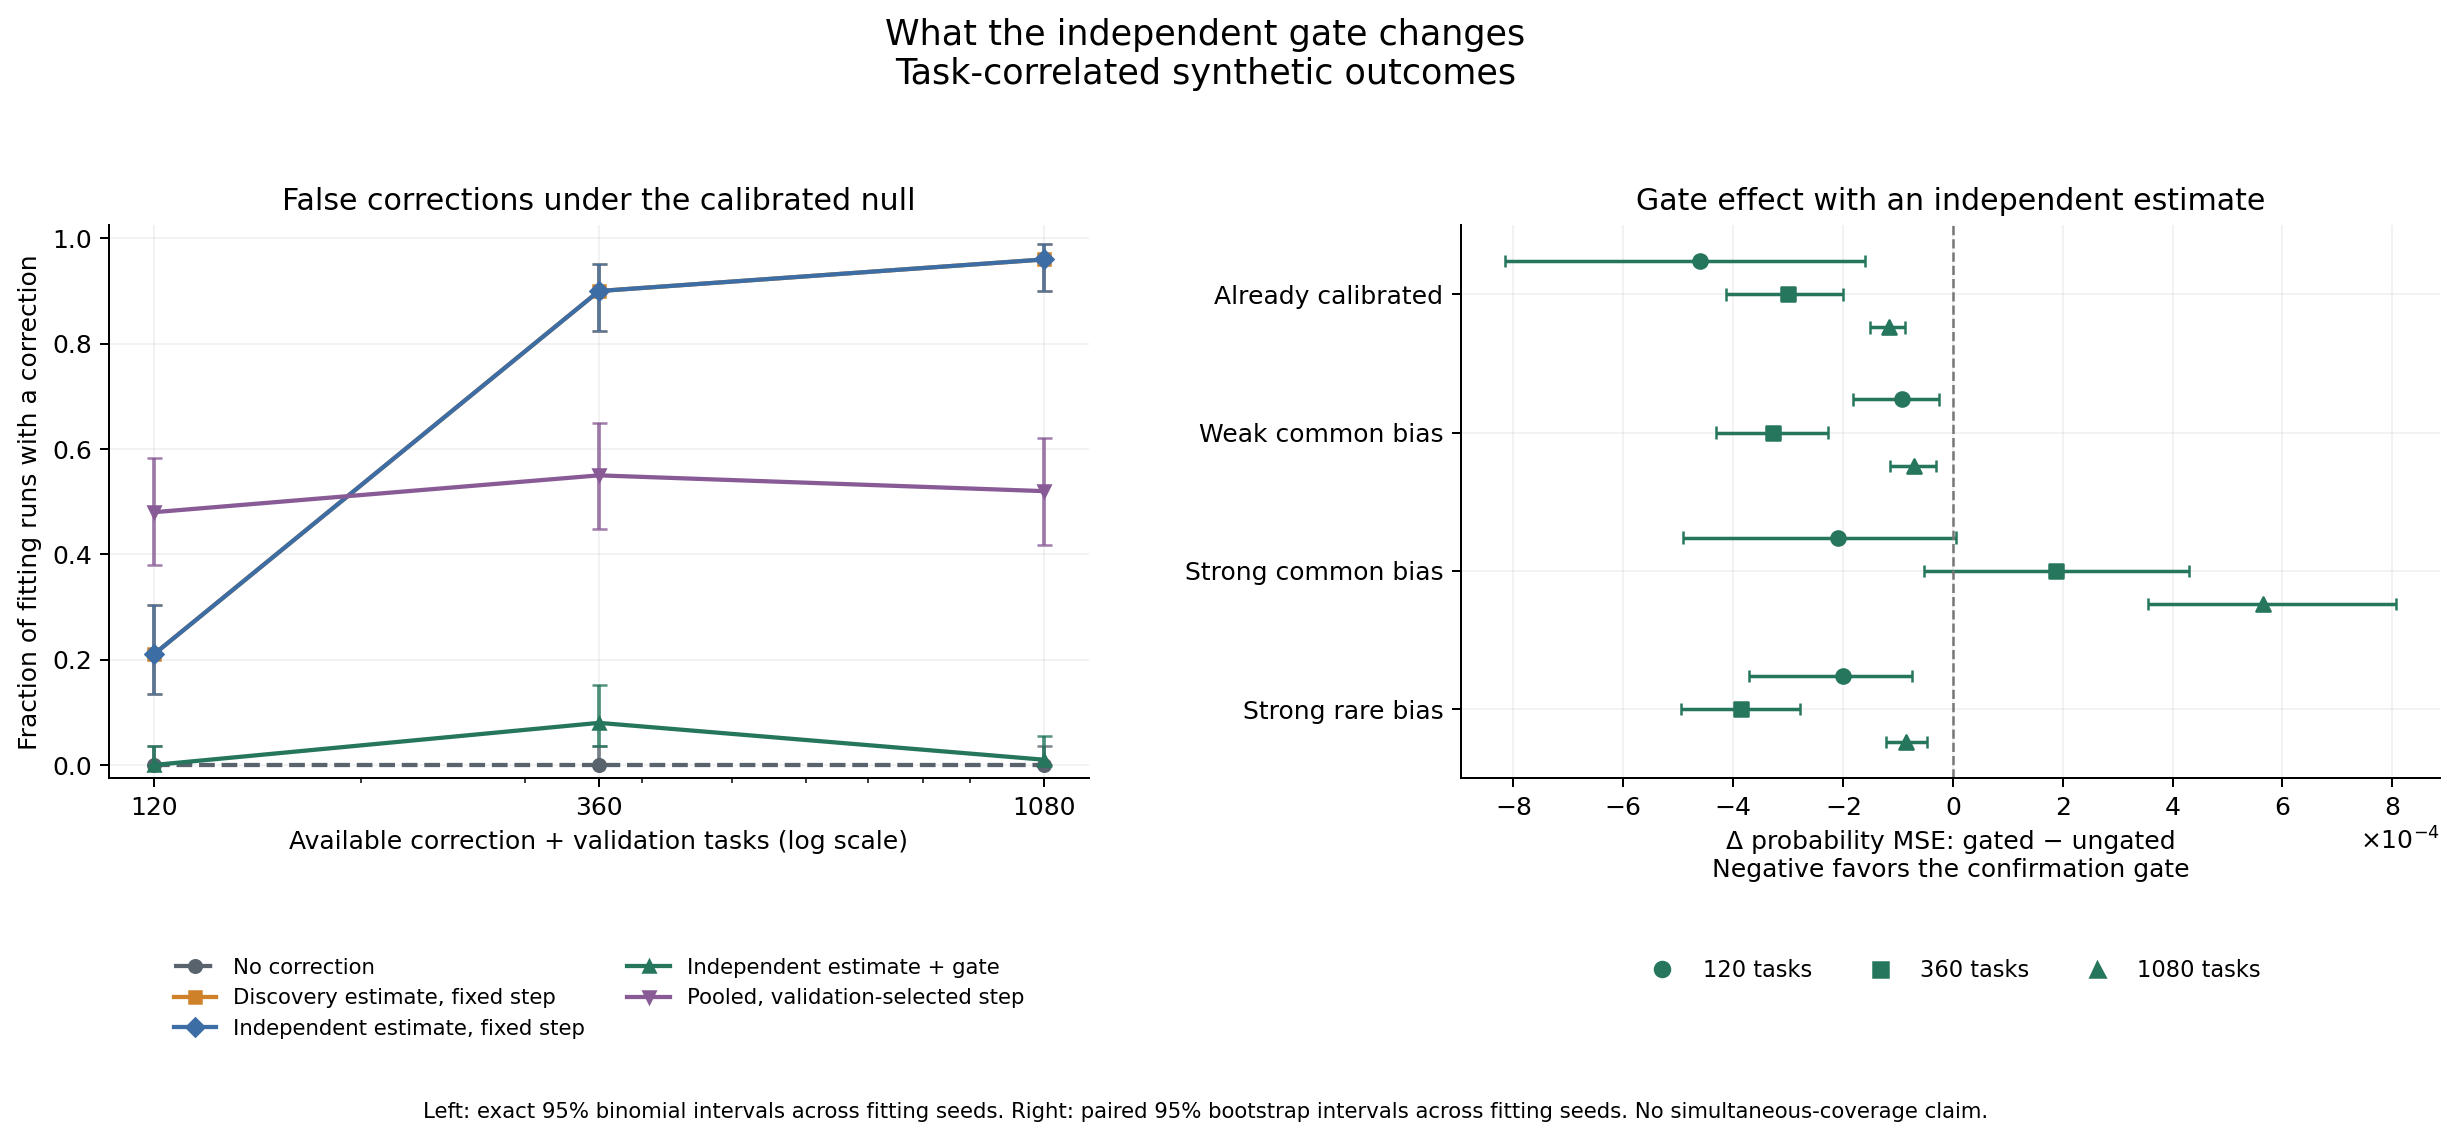

In [5]:
simulation_contrasts = pd.read_csv(RESULTS / "simulation_contrasts.csv")
primary = simulation_contrasts[simulation_contrasts["contrast"] == "gate_with_independent_estimate"]
display(primary[["scenario", "shared_uniform", "budget", "difference", "low", "high", "seeds"]])
display(Image(filename=str(RESULTS / "gate_diagnostics.png")))

## 5. Evaluate frozen models on another benchmark

The external check uses 161 Python MultiPL-E tasks. Five source-fitted pipelines at budget 339 are serialized before evaluation; their probabilities are averaged per answer. No external label selects a rule, step, predictor or calibration mapping. Upstream restrictions require evaluation-only use of these records, so published artifacts contain aggregates.

The task-bootstrap intervals condition on that frozen ensemble. These tasks are new to this study, but model-training contamination and semantic overlap are unverified. Original source prompts are not cached for an exact prompt-overlap check. Source fold means and external ensemble scores are different evaluation summaries.

,method,brier,log_loss,nonempty_brier,tasks
0,no_update,0.073983,0.268803,0.073983,161
3,discovery_gated,0.074481,0.269999,0.074481,161
6,independent_shrinkage,0.074499,0.269991,0.074499,161
4,independent_gated,0.074535,0.270127,0.074535,161
2,independent_fixed,0.074822,0.270771,0.074822,161
7,pooled_shrinkage,0.074995,0.274788,0.074995,161
1,discovery_fixed,0.076143,0.273577,0.076143,161
5,discovery_shrinkage,0.076536,0.274259,0.076536,161
8,raw_logistic,0.077476,0.281394,0.077476,161


,contrast,difference,low,high,task_clusters
0,gate_with_independent_estimate,-0.000287,-0.000693,0.000094,161
1,gate_with_reused_estimate,-0.001662,-0.003762,0.000308,161
2,independent_vs_reused_estimate,-0.001321,-0.002998,0.000229,161
3,gate_vs_tuned_independent,0.000036,-0.000303,0.000377,161
4,gate_vs_pooled_shrinkage,-0.000459,-0.001333,0.000534,161
5,gate_estimator_interaction,0.001376,-0.000224,0.003090,161


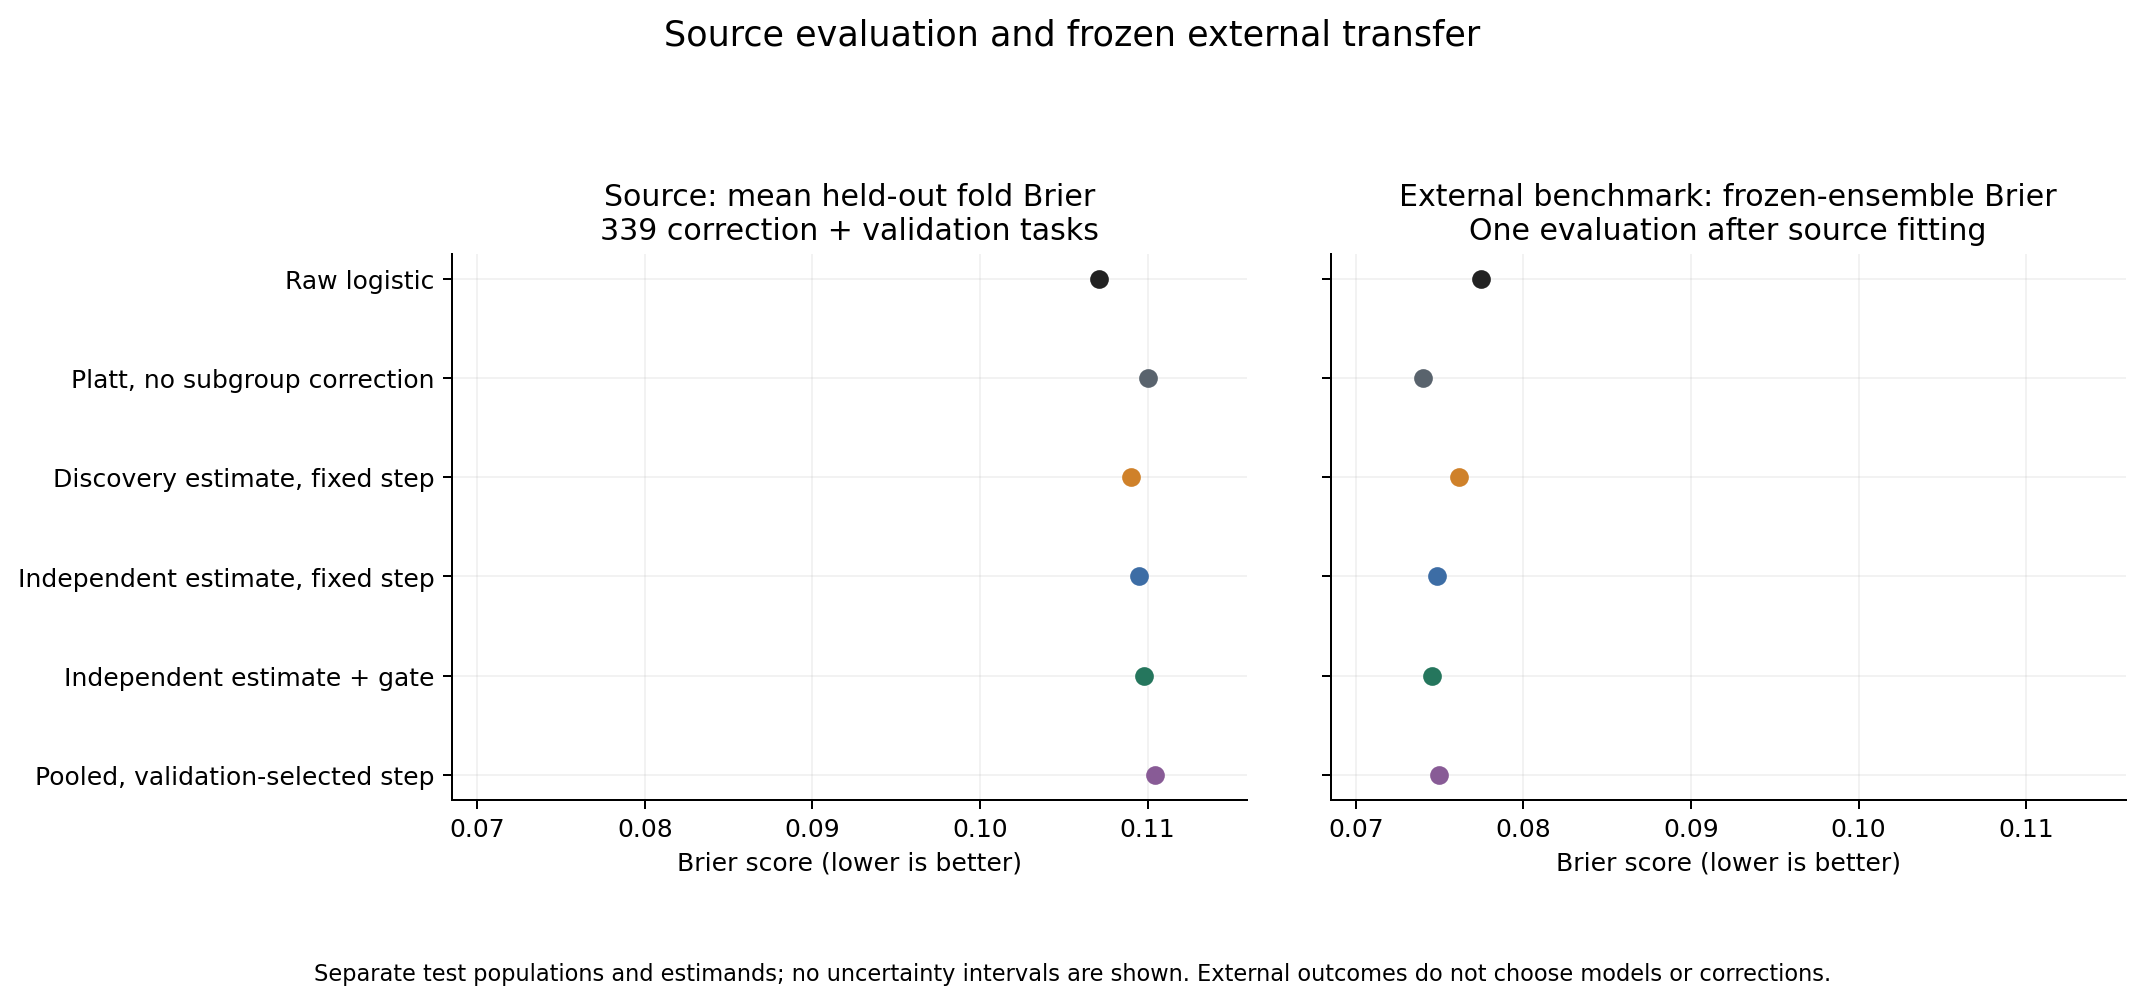

In [6]:
external = pd.read_csv(RESULTS / "external_metrics.csv")
external_record = json.loads((RESULTS / "external_record.json").read_text())
seal = json.loads((RESULTS / "source_freeze.json").read_text())
assert external_record["tasks"] == 161 and external_record["candidates"] == 1610
assert external_record["source_folds_averaged"] == 5
assert digest(RESULTS / "fitted_models.json") == seal["fitted_models_sha256"]
assert digest(RESULTS / "source_freeze.json") == external_record["source_freeze_sha256"]
display(external[["method", "brier", "log_loss", "nonempty_brier", "tasks"]].sort_values("brier"))
display(pd.read_csv(RESULTS / "external_contrasts.csv")
        [["contrast", "difference", "low", "high", "task_clusters"]])
display(Image(filename=str(RESULTS / "source_external.png")))

## Interpretation

Independent estimation removes a large part of the null distortion before adding any gate. At budget 1,080 with task-shared label noise, MSE moves from 0.001064 for the reused estimate to 0.000118 for the independent estimate and 0.000002 with confirmation. Across the six null settings, observed gated update rates range from 0% to 8%; these are finite Monte Carlo estimates, not a 5% error guarantee.

The price depends on outcome dependence. For strong common bias at budget 1,080, independent-label runs accept every proposal, so the gate changes nothing. Task-shared runs accept half and lose useful corrections: the primary MSE difference is +0.000565 [0.000355, 0.000806]. Pooled shrinkage is better in both strong-bias cases at this budget. It does not dominate every weak/rare setting.

In weak and rare task-shared cases, the gate mostly avoids deterioration by retaining the original scores. At budget 1,080, the rare task-shared case yields only 15 eligible, oracle-signal proposals out of 100 fitting seeds; discovery quality also limits the procedure.

The coding evaluations establish no clear gate benefit. Raw logistic leads source OOF Brier, while Platt/no-update leads the external ensemble comparison. The external primary difference is -0.000287 [-0.000693, 0.000094]. This is inconclusive evidence, not proof of equivalence.

The mechanism comparison and the practical budget comparison answer different questions. The findings support protection against selected noise under these conditions, with a power and label-allocation cost. They do not establish superiority over conservative calibration in general.

## Reproduce

```bash
python -m research.external --output work/new-external --protocol research/confirmation_protocol.json
python -m research.confirmation_study --output work/new-confirmation --external work/new-external
python -m research.confirmation_figures --results work/new-confirmation
python -m unittest discover -s research -t . -v
```

Use fresh directories. Python 3.13 is recommended for fresh AST feature extraction. Omitting `--external` runs source and synthetic experiments. Smoke runs use separate pilot seeds, skip external evaluation and are marked incomplete.

[Study methods and related work](CONFIRMATION_STUDY.md) describe the exact budget, gate, source restrictions and uncertainty. The protocol was versioned before this evaluation, without independent registration. This implementation and analysis were developed with AI assistance.